# Personal Finance Analyzer
Mini Project - Python Programming

**Aim:** take a bank statement CSV and find out where the money goes.

Steps: load and clean -> categorize -> charts -> unusual expenses -> repeating payments -> budget check -> forecast -> save in SQLite.

## 1. Import libraries

In [20]:
import os
import random
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

print("Libraries imported")

Libraries imported


## 2. Settings
All the things I may want to change are kept here.

* `CSV_FILE` - the bank statement file (put the Kaggle file here if you use one)
* `DAY_FIRST` - `True` for dates like 25-12-2025, `False` for dates like 2025-12-25 or 12/25/2025

In [21]:
CSV_FILE = r"bank_statement.csv"
DAY_FIRST = True

## 3. Sample data (only if I do not have a real file)
This cell makes a small fake statement **only when the file does not exist**.
If you use a Kaggle file, just put it in the same folder and this cell does nothing.

In [22]:
if not os.path.exists(CSV_FILE):
    random.seed(42)   # same random numbers every time

    # (name, lowest amount, highest amount)
    shops = [
        ("SWIGGY ORDER", 150, 600),
        ("ZOMATO ORDER", 150, 650),
        ("CAFE COFFEE DAY", 120, 380),
        ("UBER TRIP", 90, 450),
        ("IRCTC TICKET", 300, 1500),
        ("AIRTEL RECHARGE", 199, 449),
        ("KSEB BILL", 800, 2200),
        ("AMAZON ORDER", 300, 4000),
        ("FLIPKART ORDER", 400, 5000),
        ("APOLLO PHARMACY", 150, 900),
        ("PVR CINEMAS", 400, 1200),
    ]

    rows = []
    for month in range(1, 13):
        m = str(month).zfill(2)    # 1 -> "01"
        rows.append(["01-" + m + "-2025", "SALARY CREDIT", 55000, "credit"])
        rows.append(["05-" + m + "-2025", "HOUSE RENT PAID", 11500, "debit"])
        rows.append(["08-" + m + "-2025", "NETFLIX SUBSCRIPTION", 649, "debit"])
        rows.append(["12-" + m + "-2025", "SPOTIFY PREMIUM", 119, "debit"])

        # 30 random everyday expenses in every month
        for i in range(30):
            day = str(random.randint(1, 28)).zfill(2)
            name, low, high = random.choice(shops)
            amount = random.randint(low, high)
            rows.append([day + "-" + m + "-2025", name + " " + str(random.randint(1000, 9999)), amount, "debit"])

    # one very big purchase, to see if the anomaly step finds it
    rows.append(["18-03-2025", "FLIPKART ORDER 7781", 15000, "debit"])

    sample = pd.DataFrame(rows, columns=["date", "description", "amount", "type"])
    sample.to_csv(CSV_FILE, index=False)
    print("Sample file created:", CSV_FILE)
else:
    print("Using existing file:", CSV_FILE)

Using existing file: bank_statement.csv


## 4. Load the CSV and look at it
Always look at the data first.

In [23]:
df = pd.read_csv(CSV_FILE)

print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape (rows, columns): (437, 4)
Columns: ['date', 'description', 'amount', 'type']


,date,description,amount,type
0,01-01-2025,NAMMA METRO RECHARGE 4470,128.35,debit
1,01-01-2025,ZOMATO ORDER 3705,323.70,debit
2,02-01-2025,ASIANET BROADBAND BILL,742.55,debit
3,03-01-2025,DOMINOS PIZZA 6539,413.78,debit
4,03-01-2025,SALARY CREDIT,52912.00,credit


In [24]:
print(list(df.columns))

['date', 'description', 'amount', 'type']


## 5. Clean the data
1. remove duplicate rows
2. remove rows with empty cells
3. make `date` a real date
4. make descriptions UPPER CASE (so keyword search is easy)
5. make `amount` always positive (debit / credit already tells the direction)
6. make `type` only `debit` or `credit`
7. add a `month` column like `2025-03`

In [25]:
df = df.drop_duplicates()
df = df.dropna(subset=["date", "description", "amount", "type"])

df["date"] = pd.to_datetime(df["date"], dayfirst=DAY_FIRST)
df["description"] = df["description"].str.upper().str.strip()
df["amount"] = df["amount"].abs()

# type: write everything in small letters, then change short words
df["type"] = df["type"].str.lower().str.strip()
df["type"] = df["type"].replace({"dr": "debit", "cr": "credit",
                                 "withdrawal": "debit", "deposit": "credit"})

df["month"] = df["date"].dt.strftime("%Y-%m")
df = df.sort_values("date").reset_index(drop=True)

print("Types found:", df["type"].unique())   # should be only debit and credit
print("Rows after cleaning:", len(df))
df.head()

Types found: ['debit' 'credit']
Rows after cleaning: 437


,date,description,amount,type,month
0,2025-01-01,NAMMA METRO RECHARGE 4470,128.35,debit,2025-01
1,2025-01-01,ZOMATO ORDER 3705,323.70,debit,2025-01
2,2025-01-02,ASIANET BROADBAND BILL,742.55,debit,2025-01
3,2025-01-03,DOMINOS PIZZA 6539,413.78,debit,2025-01
4,2025-01-03,SALARY CREDIT,52912.00,credit,2025-01


## 6. Categorize every transaction
I made a dictionary: category -> keywords. If a keyword is inside the description, that row gets the category.

The **first match wins**, so the order matters (for example PRIME is checked in Subscriptions before AMAZON in Shopping).
Anything that matches nothing becomes `Others`.

*For a Kaggle file: look at the `Others` count below and add more keywords for your merchants.*

In [26]:
category_keywords = {
    "Food":          ["SWIGGY", "ZOMATO", "DOMINOS", "RESTAURANT", "CAFE", "CHAI", "GROCERY", "BLINKIT"],
    "Travel":        ["UBER", "OLA", "IRCTC", "METRO", "PETROL", "TAXI"],
    "Subscriptions": ["NETFLIX", "SPOTIFY", "PRIME", "HOTSTAR"],
    "Shopping":      ["AMAZON", "FLIPKART", "MYNTRA", "NYKAA"],
    "Rent":          ["RENT"],
    "Health":        ["APOLLO", "PHARMACY", "HOSPITAL", "DOCTOR", "GYM"],
    "Entertainment": ["PVR", "BOOKMYSHOW", "CINEMA", "MOVIE"],
    "Bills":         ["KSEB", "ELECTRIC", "AIRTEL", "JIO", "BROADBAND", "GAS", "BILL", "RECHARGE"],
}


def find_category(description):
    for category in category_keywords:
        for word in category_keywords[category]:
            if word in description:
                return category
    return "Others"


df["category"] = df["description"].apply(find_category)

print(df["category"].value_counts())
print()
print("Rows in Others:", (df["category"] == "Others").sum(), "out of", len(df))

category
Travel           88
Food             88
Bills            80
Others           45
Subscriptions    36
Health           33
Shopping         33
Entertainment    22
Rent             12
Name: count, dtype: int64

Rows in Others: 45 out of 437


## 7. Charts: where does the money go?
Only **debit** rows are spending, so I filter them first.

category
Rent             137995.32
Shopping          71841.06
Others            58396.25
Bills             51408.97
Health            50152.82
Food              45783.29
Travel            35347.57
Entertainment     14232.86
Subscriptions     12807.97
Name: amount, dtype: float64


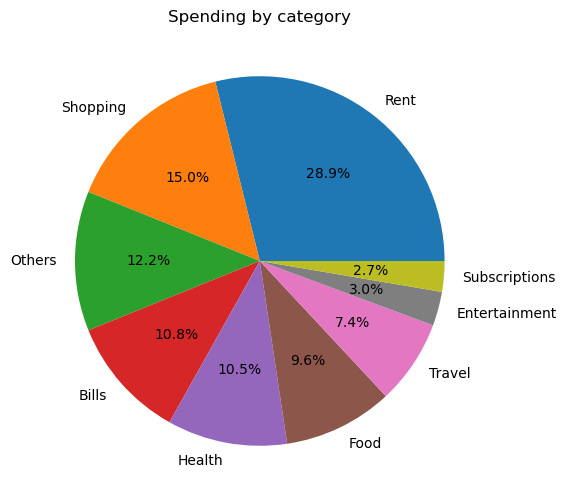

In [27]:
debits = df[df["type"] == "debit"]

spend_by_category = debits.groupby("category")["amount"].sum().sort_values(ascending=False)
print(spend_by_category)

plt.figure(figsize=(6, 6))
plt.pie(spend_by_category, labels=spend_by_category.index, autopct="%1.1f%%")
plt.title("Spending by category")
plt.show()

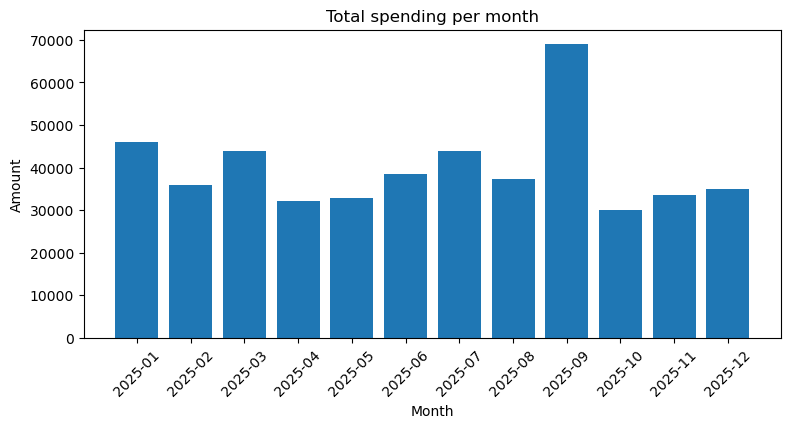

In [28]:
monthly_spend = debits.groupby("month")["amount"].sum()

plt.figure(figsize=(9, 4))
plt.bar(monthly_spend.index, monthly_spend.values)
plt.title("Total spending per month")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.show()

**My observation:** (write here which category is biggest and which month has the highest spending, and why you think so)

## 8. Top 5 expenses and savings
Savings rate = (money in - money out) / money in x 100

In [29]:
top5 = debits.nlargest(5, "amount")
print("Top 5 biggest expenses:")
print(top5[["date", "description", "category", "amount"]])

total_in = df[df["type"] == "credit"]["amount"].sum()
total_out = df[df["type"] == "debit"]["amount"].sum()
savings = total_in - total_out

print()
print("Money in :", round(total_in, 2))
print("Money out:", round(total_out, 2))
print("Savings  :", round(savings, 2))
if total_in > 0:
    print("Savings rate:", round(100 * savings / total_in, 1), "%")

Top 5 biggest expenses:
          date            description  category    amount
301 2025-09-07  RELIANCE DIGITAL 4432    Others  28000.00
106 2025-03-18    FLIPKART ORDER 7781  Shopping  15000.00
409 2025-12-04        HOUSE RENT PAID      Rent  11598.69
375 2025-11-06        HOUSE RENT PAID      Rent  11578.58
298 2025-09-05        HOUSE RENT PAID      Rent  11567.18

Money in : 652775.0
Money out: 477966.11
Savings  : 174808.89
Savings rate: 26.8 %


## 9. Unusual (anomaly) expenses
Idea: inside each category, an expense is unusual if it is bigger than

`mean + 2 x standard deviation`

I check **each category separately** because 2000 rupees is big for Food but small for Rent.
Categories with fewer than 5 rows are skipped because there is too little data.

In [30]:
anomaly_list = []

for category in debits["category"].unique():
    group = debits[debits["category"] == category]

    if len(group) < 5:
        continue    # too few rows

    mean = group["amount"].mean()
    std = group["amount"].std()
    limit = mean + 2 * std

    big = group[group["amount"] > limit]
    anomaly_list.append(big)

if len(anomaly_list) > 0:
    anomalies = pd.concat(anomaly_list)
else:
    anomalies = pd.DataFrame()

# mark them in the main table (used later in SQL)
df["is_anomaly"] = False
if len(anomalies) > 0:
    df.loc[anomalies.index, "is_anomaly"] = True

print("Number of unusual expenses:", len(anomalies))
if len(anomalies) > 0:
    print(anomalies.sort_values("amount", ascending=False)[["date", "description", "category", "amount"]].head(10))

Number of unusual expenses: 10
          date                  description       category    amount
301 2025-09-07        RELIANCE DIGITAL 4432         Others  28000.00
106 2025-03-18          FLIPKART ORDER 7781       Shopping  15000.00
204 2025-06-22  RESTAURANT FAMILY BILL 8891           Food   9000.00
236 2025-07-14         APOLLO PHARMACY 9090         Health   6800.00
379 2025-11-08     IRCTC TICKET PNR 5566771         Travel   4500.00
302 2025-09-09                    KSEB BILL          Bills   2193.00
163 2025-05-10                    KSEB BILL          Bills   1893.00
420 2025-12-15                    KSEB BILL          Bills   1890.00
59  2025-02-10                    KSEB BILL          Bills   1665.00
94  2025-03-08             PVR CINEMAS 2245  Entertainment   1176.07


**My observation:** (write here which unusual expenses were found and whether they make sense)

## 10. Recurring payments
Rent, Netflix, Spotify... are paid every month for the **same amount**.

Rule: a merchant is recurring if it appears in **3 or more months** and the amounts hardly change (standard deviation less than 5% of the mean).

Descriptions have random numbers (`SWIGGY ORDER 4821`), so first I remove the words that are only digits to get a merchant name.

In [31]:
def get_merchant(description):
    words = description.split()
    clean_words = []
    for word in words:
        if not word.isdigit():
            clean_words.append(word)
    return " ".join(clean_words)


df["merchant"] = df["description"].apply(get_merchant)
debits = df[df["type"] == "debit"]     # take debits again so it has the merchant column

recurring_list = []

for merchant in debits["merchant"].unique():
    group = debits[debits["merchant"] == merchant]

    months_seen = group["month"].nunique()
    if months_seen < 3:
        continue

    mean = group["amount"].mean()
    std = group["amount"].std()

    if std < 0.05 * mean:
        recurring_list.append({
            "merchant": merchant,
            "months_seen": months_seen,
            "average_amount": round(mean, 2),
            "yearly_cost": round(mean * 12, 2),
        })

recurring = pd.DataFrame(recurring_list)

if len(recurring) > 0:
    recurring = recurring.sort_values("yearly_cost", ascending=False)
    print(recurring.to_string(index=False))
    print()
    print("Total yearly cost of recurring payments:", recurring["yearly_cost"].sum())
else:
    print("No recurring payments found")

               merchant  months_seen  average_amount  yearly_cost
        HOUSE RENT PAID           12        11499.61    137995.32
 FITNESS GYM MEMBERSHIP           12         2501.55     30018.57
   NETFLIX SUBSCRIPTION           12          648.94      7787.22
AMAZON PRIME MEMBERSHIP           12          299.67      3596.07
        SPOTIFY PREMIUM           12          118.72      1424.68

Total yearly cost of recurring payments: 180821.86000000002


**My observation:** (write here which payments repeat. Why is KSEB / the electricity bill NOT in the list? Hint: its amount changes every month)

## 11. Budget check
I set a monthly limit for each category and compare it with the spending of **one month**.

* below 80% -> OK
* 80% or more -> WARNING
* 100% or more -> ALERT

In [32]:
budgets = {
    "Food": 8000,
    "Travel": 5000,
    "Bills": 6000,
    "Shopping": 10000,
    "Subscriptions": 1500,
    "Rent": 12000,
    "Health": 4000,
    "Entertainment": 3000,
    "Others": 3000,
}

budget_month = "2025-03"            # change this to a month that is in your data
if budget_month not in list(df["month"]):
    budget_month = df["month"].max()   # otherwise use the last month
print("Checking month:", budget_month)

month_debits = df[(df["type"] == "debit") & (df["month"] == budget_month)]
spent_per_category = month_debits.groupby("category")["amount"].sum()

budget_rows = []
for category in budgets:
    limit = budgets[category]
    spent = spent_per_category.get(category, 0)    # 0 if nothing was spent
    percent = 100 * spent / limit

    if percent >= 100:
        status = "ALERT"
    elif percent >= 80:
        status = "WARNING"
    else:
        status = "OK"

    budget_rows.append({"category": category, "limit": limit,
                        "spent": round(spent, 2), "percent": round(percent, 1),
                        "status": status})

budget_report = pd.DataFrame(budget_rows)
print(budget_report.to_string(index=False))

Checking month: 2025-03
     category  limit    spent  percent  status
         Food   8000  3334.80     41.7      OK
       Travel   5000  3722.60     74.5      OK
        Bills   6000  3454.76     57.6      OK
     Shopping  10000 15000.00    150.0   ALERT
Subscriptions   1500  1062.25     70.8      OK
         Rent  12000 11434.52     95.3 WARNING
       Health   4000  2505.19     62.6      OK
Entertainment   3000  1176.07     39.2      OK
       Others   3000  2126.65     70.9      OK


## 12. Forecast next month with Linear Regression
Linear Regression draws the best straight line through the points.

* x = month number (1, 2, 3, ...)
* y = total spending of that month

Then I ask the line: what is the value for the next month number?

**Limitation:** only about 12 points, so this is a rough trend, not a promise.
(If the first or last month in a Kaggle file is incomplete, the forecast will be off.)

Predicted spending for next month: 38990.85


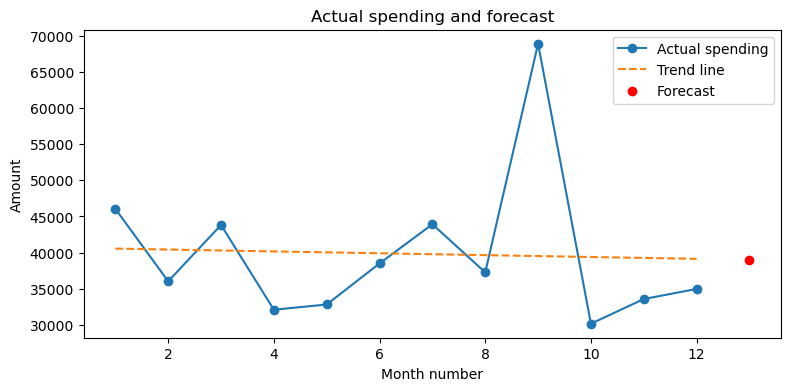

In [33]:
monthly_spend = debits.groupby("month")["amount"].sum()

x = np.arange(1, len(monthly_spend) + 1).reshape(-1, 1)   # sklearn needs a 2D column
y = monthly_spend.values

model = LinearRegression()
model.fit(x, y)

next_month_number = len(monthly_spend) + 1
prediction = model.predict([[next_month_number]])[0]

print("Predicted spending for next month:", round(prediction, 2))

plt.figure(figsize=(9, 4))
plt.plot(x.ravel(), y, marker="o", label="Actual spending")
plt.plot(x.ravel(), model.predict(x), linestyle="--", label="Trend line")
plt.scatter([next_month_number], [prediction], color="red", label="Forecast")
plt.title("Actual spending and forecast")
plt.xlabel("Month number")
plt.ylabel("Amount")
plt.legend()
plt.show()

**My observation:** (is spending going up or down? Is the forecast believable?)

## 13. Save to SQLite and ask SQL questions
SQLite is a database that comes with Python and lives in one file.
I save the cleaned table and then ask questions with SQL.

In [34]:
table_to_save = df.copy()
table_to_save["date"] = table_to_save["date"].dt.strftime("%Y-%m-%d")   # store dates as text

connection = sqlite3.connect("finance.db")
table_to_save.to_sql("transactions", connection, if_exists="replace", index=False)
print("Saved", len(table_to_save), "rows into finance.db")

Saved 437 rows into finance.db


In [35]:
# Query 1: total spending per category
query1 = '''
SELECT category, ROUND(SUM(amount), 2) AS total_spent
FROM transactions
WHERE type = 'debit'
GROUP BY category
ORDER BY total_spent DESC
'''
print(pd.read_sql(query1, connection))

# Query 2: top 5 merchants by total spending
query2 = '''
SELECT merchant, COUNT(*) AS times, ROUND(SUM(amount), 2) AS total_spent
FROM transactions
WHERE type = 'debit'
GROUP BY merchant
ORDER BY total_spent DESC
LIMIT 5
'''
print()
print(pd.read_sql(query2, connection))

connection.close()

        category  total_spent
0           Rent    137995.32
1       Shopping     71841.06
2         Others     58396.25
3          Bills     51408.97
4         Health     50152.82
5           Food     45783.29
6         Travel     35347.57
7  Entertainment     14232.86
8  Subscriptions     12807.97

                 merchant  times  total_spent
0         HOUSE RENT PAID     12    137995.32
1            AMAZON ORDER     17     38503.54
2          FLIPKART ORDER     10     33337.52
3  FITNESS GYM MEMBERSHIP     12     30018.57
4        RELIANCE DIGITAL      1     28000.00


## 14. Conclusion

**What I did:** cleaned a bank statement, put each transaction into a category, found unusual expenses and repeating payments, checked a budget and forecast next month's spending, and saved everything in SQLite.

**Limitations**
1. Keyword rules do not know new merchants - they fall into `Others` until I add a keyword.
2. The forecast uses only about 12 points, so it is only a rough trend.
3. `mean + 2 x std` works best when the amounts are roughly bell shaped.
4. Fake sample data is cleaner than a real bank statement.

**Future scope:** a web dashboard (Gradio), learning categories with machine learning, reading PDF statements.

**Problems I faced:** (write 2-3 real problems you had, for example date formats or the order of categories)